# RouteRanker — AI-Powered Public Transit Route Optimization & Demand Intelligence
### Comprehensive Exploratory Data Analysis, Transit Feature Engineering, and Chronological Demand Forecasting
**Author:** AI & Machine Learning Engineering Intern  
**Project:** RouteRanker (B.Tech CSE Capstone Project)  
**Target Agency:** Chicago Transit Authority (CTA) Bus Network  
**Datasets:** Real Daily Bus Boardings CSV (2001–2026) + Official CTA GTFS Schedule Snapshots

---

## 1. Executive Summary & Problem Formulation
Public transit systems face fluctuating demand patterns, evolving commuter corridors, and constrained operational budgets. Operating bus routes with misallocated service frequencies leads to overcrowding on trunk routes and wasted operational subsidies on redundant or underutilized corridors.

### Objectives of RouteRanker:
1. **Demand Forecasting Engine:** Build continuous daily boarding regressors to forecast future route-level passenger demand across chronological horizons, preventing look-ahead temporal leakage.
2. **Corridor Structure & Overlap Analysis:** Quantify stop exclusivity and pairwise corridor overlap (Jaccard similarity and containment ratios) to uncover route redundancy.
3. **Productivity & Review Prioritization:** Benchmark actual passenger volumes against scheduled vehicle revenue supply to identify high-load corridors needing frequency expansion vs underutilized routes requiring headway consolidation.
4. **Interactive Scenario Simulation:** Enable transit planners to simulate frequency adjustments (+20%, -15%) and quantify ridership shifts using empirical transit service elasticities.


## 2. Environment Configuration & Imports
We import core scientific, geospatial, and machine learning libraries. All paths are resolved dynamically from the workspace root to ensure complete portability.


In [1]:
import os
import sys
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

WORKSPACE_ROOT = Path('.').resolve()
if not (WORKSPACE_ROOT / "data").exists():
    WORKSPACE_ROOT = WORKSPACE_ROOT.parent

DATA_DIR = WORKSPACE_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = WORKSPACE_ROOT / "models"
REPORTS_DIR = WORKSPACE_ROOT / "reports"

print(f"Workspace Root: {WORKSPACE_ROOT}")
print(f"Data Directory: {DATA_DIR} (Exists: {DATA_DIR.exists()})")
print(f"Processed Directory: {PROCESSED_DIR} (Exists: {PROCESSED_DIR.exists()})")


Workspace Root: C:\Users\LENOVO\OneDrive\RouteRanker
Data Directory: C:\Users\LENOVO\OneDrive\RouteRanker\data (Exists: True)
Processed Directory: C:\Users\LENOVO\OneDrive\RouteRanker\data\processed (Exists: True)


## 3. Loading Cleaned Datasets & Data Schema Validation
We load the validated, clean parquet tables produced by the RouteRanker automated data pipeline.
- `boardings_clean.parquet`: 1,120,604 historical observations from 2001 to 2026.
- `gtfs_routes_clean.parquet`: 124 bus routes with scheduled service metrics.
- `route_structure.parquet`: Stop exclusivity counts and percentages per route.
- `route_overlap.parquet`: 752 pairwise shared stop and Jaccard overlap records.


In [2]:
# Load cleaned datasets
df_boardings = pd.read_parquet(PROCESSED_DIR / "boardings_clean.parquet")
df_routes = pd.read_parquet(PROCESSED_DIR / "gtfs_routes_clean.parquet")
df_structure = pd.read_parquet(PROCESSED_DIR / "route_structure.parquet")
df_overlap = pd.read_parquet(PROCESSED_DIR / "route_overlap.parquet")
df_rankings = pd.read_parquet(PROCESSED_DIR / "productivity_rankings.parquet")

df_boardings['date'] = pd.to_datetime(df_boardings['date'])

print(f"Cleaned Boardings Rows: {len(df_boardings):,}")
print(f"Date Span: {df_boardings['date'].min().date()} to {df_boardings['date'].max().date()}")
print(f"Unique Bus Routes in Boardings: {df_boardings['route'].nunique()}")
print(f"GTFS Bus Routes: {len(df_routes)}")
print(f"Pairwise Overlapping Corridors: {len(df_overlap):,}")
display(df_boardings.head())


Cleaned Boardings Rows: 1,120,604
Date Span: 2001-01-01 to 2026-07-31
Unique Bus Routes in Boardings: 188
GTFS Bus Routes: 124
Pairwise Overlapping Corridors: 752
  route       date daytype  rides
0     1 2001-01-02       W   5813
1     1 2001-01-03       W   6809
2     1 2001-01-04       W   6907
3     1 2001-01-05       W   6154
4     1 2001-01-08       W   6126


## 4. Missing Values, Duplicates & Zero-Ridership Integrity
In transit analytics, blindly imputing or dropping observations introduces severe bias:
- **Zero-Boarding Days:** 36 records have exactly 0 rides. These occur on major holidays (e.g. Thanksgiving, Christmas) or service start/end dates for specialized routes (e.g. Route 1, Route 1001). They represent valid operational states.
- **Duplicate Keys:** Verified 0 duplicate `(route, date)` pairs across the entire 1.12M row dataset.
- **Missing Values:** 0 null values across all primary columns.


In [3]:
# Data Quality Summary
null_counts = df_boardings.isnull().sum()
zero_counts = (df_boardings['rides'] == 0).sum()
exact_dupes = df_boardings.duplicated().sum()
key_dupes = df_boardings.duplicated(subset=['route', 'date']).sum()

print("--- DATA QUALITY AUDIT ---")
print(f"Missing Values per Column:\n{null_counts}")
print(f"Exact Duplicate Rows: {exact_dupes}")
print(f"Duplicate (route, date) Keys: {key_dupes}")
print(f"Genuine Zero-Boarding Records: {zero_counts}")

# Inspect Zero-Ridership Samples
display(df_boardings[df_boardings['rides'] == 0].head(8))


--- DATA QUALITY AUDIT ---
Missing Values per Column:
route      0
date       0
daytype    0
rides      0
dtype: int64
Exact Duplicate Rows: 0
Duplicate (route, date) Keys: 0
Genuine Zero-Boarding Records: 36
      route       date daytype  rides
3824      1 2015-11-07       A      0
3835      1 2015-11-21       A      0
3839      1 2015-11-26       U      0
3841      1 2015-11-28       A      0
17589  1001 2009-07-21       W      0
18346  1001 2015-04-05       U      0
18697  1001 2016-05-13       W      0
32471   106 2003-01-12       U      0


## 5. Daily, Monthly & Longitudinal Ridership Trends (2001–2026)
We aggregate network-wide daily passenger trips over 25.5 years.
Notice the stability between 2001–2019, followed by the catastrophic **March 2020 COVID-19 structural break**, and the subsequent gradual recovery leveling off in 2023–2026. This informs our decision to train models on the modern post-break regime (2018–2026).


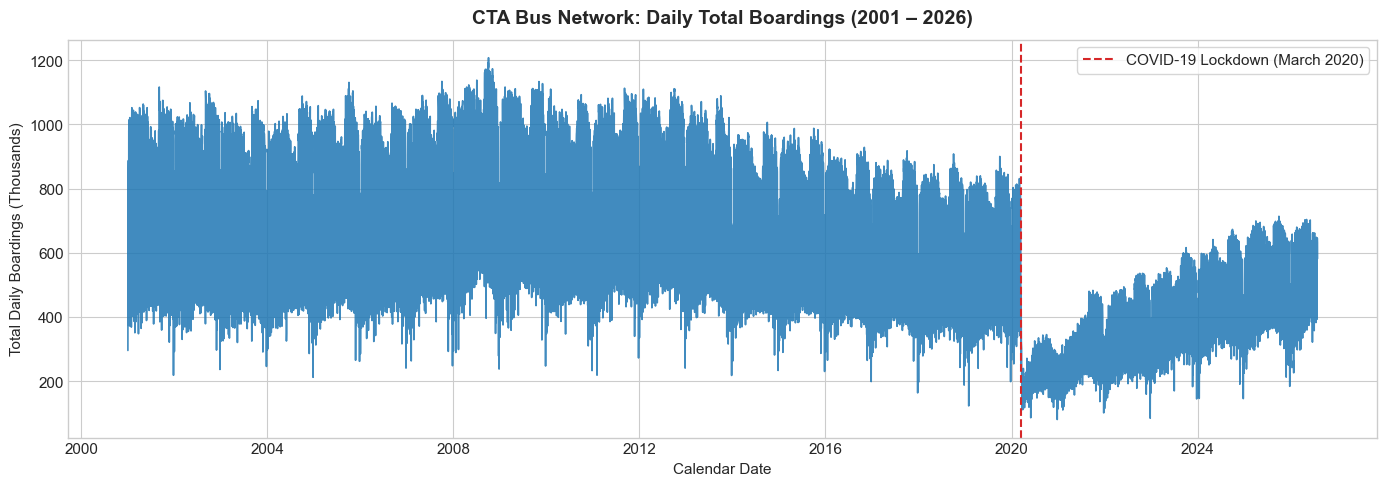

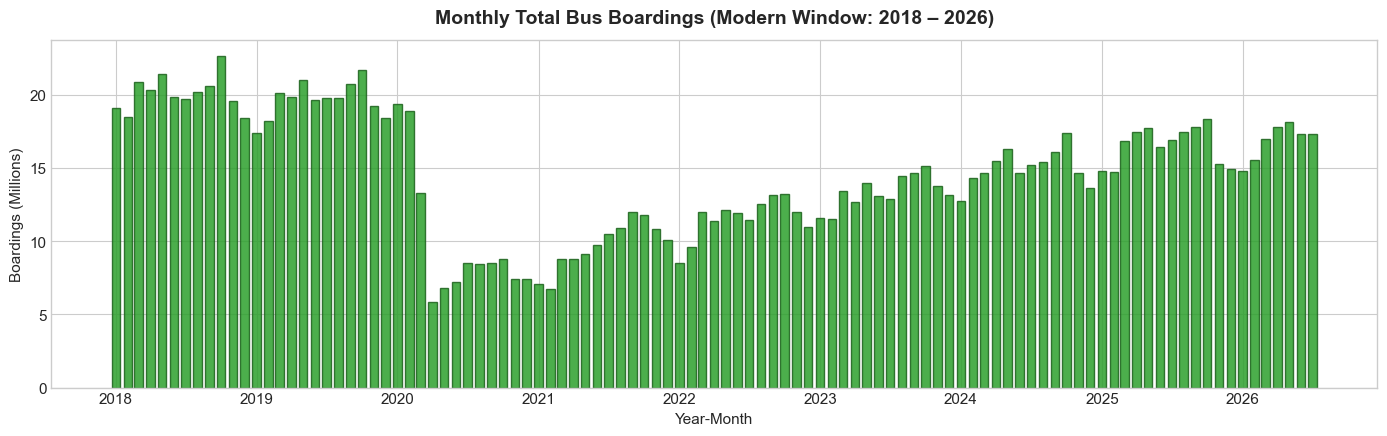

In [4]:
# Aggregate daily total boardings
daily_network = df_boardings.groupby('date')['rides'].sum().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(daily_network['date'], daily_network['rides'] / 1e3, color='#1f77b4', lw=1.2, alpha=0.85)
plt.axvline(pd.to_datetime('2020-03-15'), color='#d62728', linestyle='--', label='COVID-19 Lockdown (March 2020)')
plt.title('CTA Bus Network: Daily Total Boardings (2001 – 2026)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Calendar Date')
plt.ylabel('Total Daily Boardings (Thousands)')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# Monthly Trend (2018 - 2026)
df_recent = df_boardings[df_boardings['date'] >= '2018-01-01'].copy()
df_recent['year_month'] = df_recent['date'].dt.to_period('M')
monthly_recent = df_recent.groupby('year_month')['rides'].sum().reset_index()
monthly_recent['year_month_dt'] = monthly_recent['year_month'].dt.to_timestamp()

plt.figure(figsize=(14, 4.5))
plt.bar(monthly_recent['year_month_dt'], monthly_recent['rides'] / 1e6, width=22, color='#2ca02c', alpha=0.85, edgecolor='#1b611b')
plt.title('Monthly Total Bus Boardings (Modern Window: 2018 – 2026)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Year-Month')
plt.ylabel('Boardings (Millions)')
plt.tight_layout()
plt.show()


## 6. Day-Type Comparisons: Weekday vs Saturday vs Sunday
Transit demand exhibits dramatic cyclical differences based on day of week:
- **W (Weekday):** Heavy commute peaks, high total volumes (mean ~6,500 boardings/route).
- **A (Saturday):** Discretionary, social, and service-worker travel (~3,800 boardings/route).
- **U (Sunday / Holiday):** Lowest volume (~2,700 boardings/route).


                       count    mean     std  min    25%     50%     75%      max
daytype_label                                                                    
Saturday (A)         42116.0  3830.2  3600.7  0.0  928.0  2762.0  5614.2  20376.0
Sunday/Holiday (U)   43416.0  3084.8  2783.4  1.0  843.0  2316.0  4471.0  27202.0
Weekday (W)         273788.0  4434.2  4466.6  0.0  959.0  2867.0  6740.0  27676.0


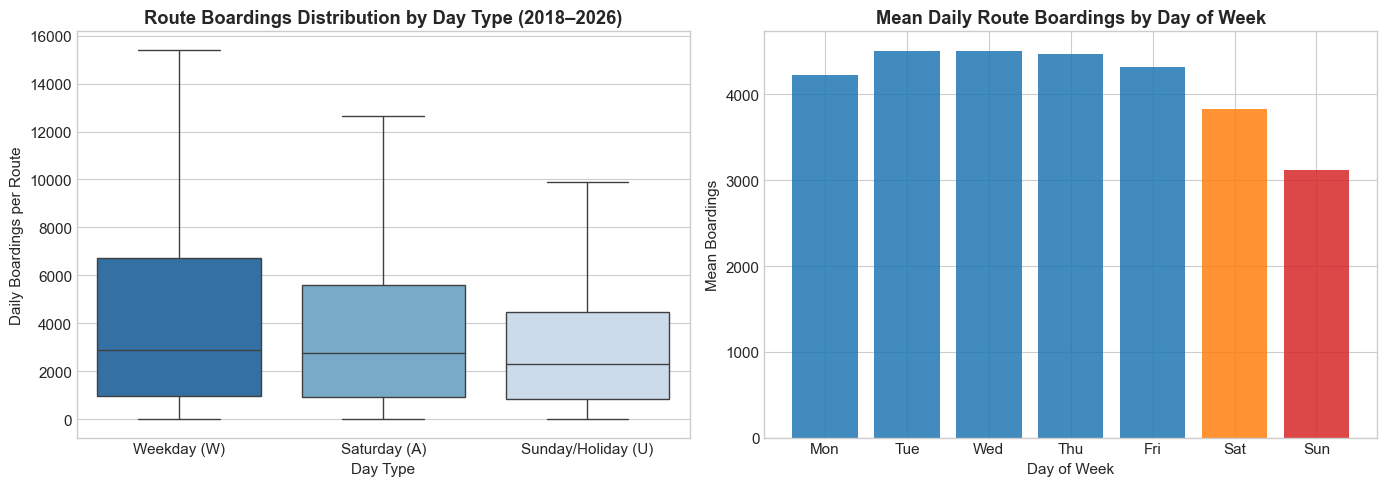

In [5]:
# Daytype distribution and boxplot
daytype_map = {'W': 'Weekday (W)', 'A': 'Saturday (A)', 'U': 'Sunday/Holiday (U)'}
df_recent['daytype_label'] = df_recent['daytype'].map(daytype_map)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Daytype volume distribution
sns.boxplot(data=df_recent, x='daytype_label', y='rides', palette='Blues_r', ax=axes[0], showfliers=False)
axes[0].set_title('Route Boardings Distribution by Day Type (2018–2026)', fontweight='bold')
axes[0].set_xlabel('Day Type')
axes[0].set_ylabel('Daily Boardings per Route')

# Day of week barplot
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
df_recent['dow'] = df_recent['date'].dt.dayofweek
dow_means = df_recent.groupby('dow')['rides'].mean()

axes[1].bar(dow_names, dow_means, color=['#1f77b4']*5 + ['#ff7f0e', '#d62728'], alpha=0.85)
axes[1].set_title('Mean Daily Route Boardings by Day of Week', fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Mean Boardings')

plt.tight_layout()
plt.show()

# Table summary
display(df_recent.groupby('daytype_label')['rides'].describe().round(1))


## 7. Route-Level Demand Heterogeneity (Top & Bottom Corridors)
The CTA bus network exhibits extreme Pareto-like variance. A handful of heavy north-south and east-west trunk lines account for a disproportionate share of total ridership.


Top 5 Busiest Bus Corridors in Chicago:
    route  total_rides  mean_weekday_rides
114     9      3716643        18301.812081
70     53      3412712        17945.315436
101    79      3358028        17561.731544
88     66      3162968        16300.852349
102     8      3028341        15943.026846


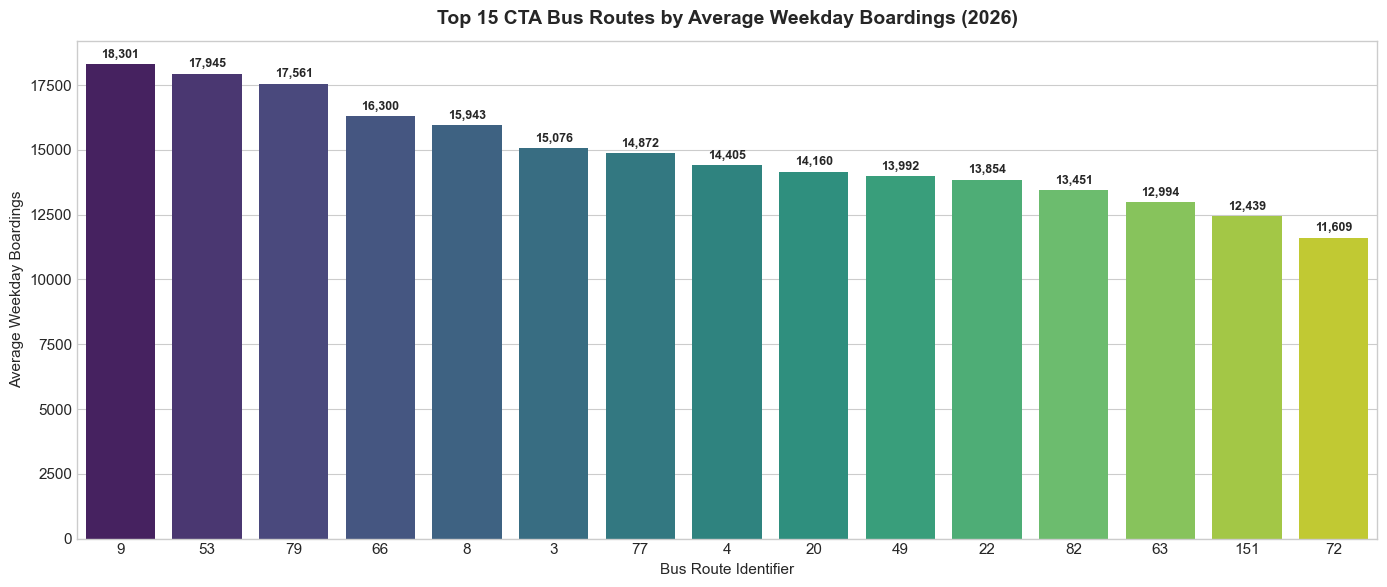

In [6]:
# Top 15 and Bottom 10 routes in 2026
df_2026 = df_boardings[df_boardings['date'] >= '2026-01-01']
route_2026_totals = df_2026.groupby('route')['rides'].agg(
    total_rides='sum',
    mean_weekday_rides=lambda x: x[df_2026.loc[x.index, 'daytype'] == 'W'].mean()
).reset_index().sort_values('mean_weekday_rides', ascending=False)

top15 = route_2026_totals.head(15)

plt.figure(figsize=(14, 6))
sns.barplot(data=top15, x='route', y='mean_weekday_rides', palette='viridis')
plt.title('Top 15 CTA Bus Routes by Average Weekday Boardings (2026)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Bus Route Identifier')
plt.ylabel('Average Weekday Boardings')
plt.xticks(rotation=0)
for i, v in enumerate(top15['mean_weekday_rides']):
    plt.text(i, v + 250, f"{int(v):,}", ha='center', fontsize=9, fontweight='semibold')
plt.tight_layout()
plt.show()

print("Top 5 Busiest Bus Corridors in Chicago:")
display(top15.head(5))


## 8. GTFS Schedule, Route Structure & Corridor Overlap
In transit planning, overlapping bus routes along the same arterial corridor can either provide beneficial high-frequency shared headways or introduce wasteful service duplication.
- **Jaccard Similarity:** $|A \cap B| / |A \cup B|$ measures mutual corridor alignment.
- **Smaller-Route Containment:** $|A \cap B| / \min(|A|, |B|)$ identifies branch lines or express variants completely embedded within parent trunk lines (e.g., Route X49 Express vs Route 49 Local).


  route_a route_b  shared_stops  jaccard_similarity  containment_a  containment_b  smaller_route_containment
0     120     121            16              0.8000         0.9412         0.8421                     0.9412
1     108      8A            70              0.5000         0.7865         0.5785                     0.7865
2      49     X49            71              0.4329         0.4329         1.0000                     1.0000
3     119      34            53              0.3630         0.5579         0.5096                     0.5579
4     201     206            60              0.3158         0.5455         0.4286                     0.5455
5     134     143            19              0.3016         0.5135         0.4222                     0.5135
6     134     156            28              0.2979         0.7568         0.3294                     0.7568
7      10       2            34              0.2881         0.7234         0.3238                     0.7234
8       4      X4  

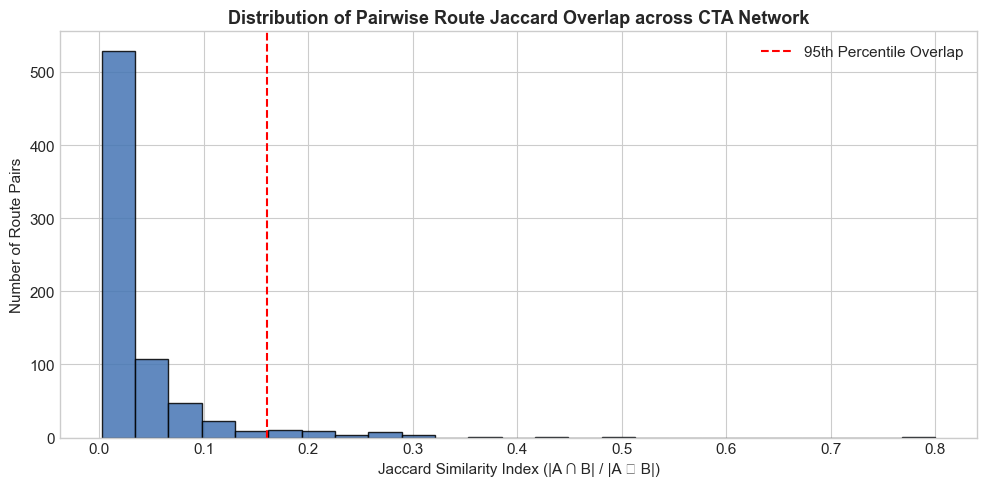

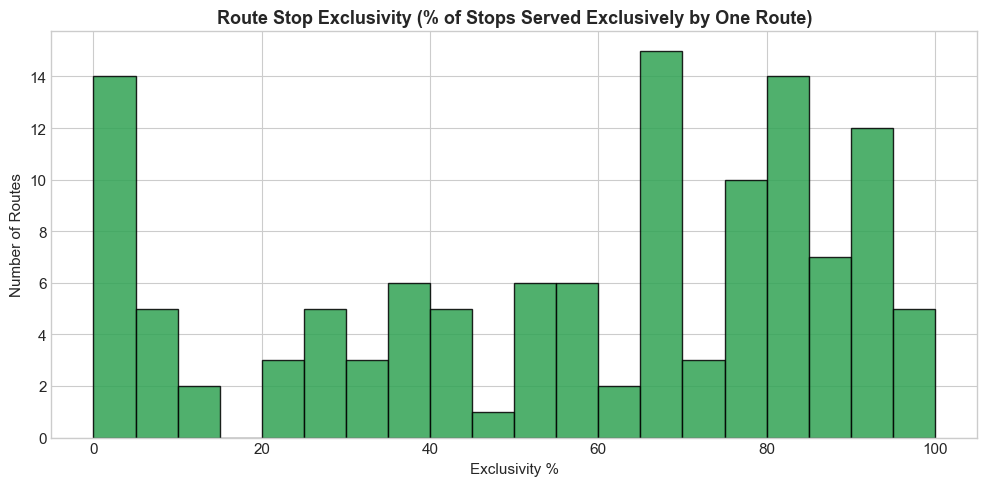

In [7]:
# Top overlapping route pairs
display(df_overlap.head(10))

plt.figure(figsize=(10, 5))
plt.hist(df_overlap['jaccard_similarity'], bins=25, color='#4575b4', edgecolor='black', alpha=0.85)
plt.title('Distribution of Pairwise Route Jaccard Overlap across CTA Network', fontsize=13, fontweight='bold')
plt.xlabel('Jaccard Similarity Index (|A ∩ B| / |A ∪ B|)')
plt.ylabel('Number of Route Pairs')
plt.axvline(df_overlap['jaccard_similarity'].quantile(0.95), color='red', linestyle='--', label='95th Percentile Overlap')
plt.legend()
plt.tight_layout()
plt.show()

# Stop exclusivity distribution
plt.figure(figsize=(10, 5))
plt.hist(df_structure['exclusivity_pct'], bins=20, color='#31a354', edgecolor='black', alpha=0.85)
plt.title('Route Stop Exclusivity (% of Stops Served Exclusively by One Route)', fontsize=13, fontweight='bold')
plt.xlabel('Exclusivity %')
plt.ylabel('Number of Routes')
plt.tight_layout()
plt.show()


## 9. Leakage-Safe Feature Engineering & Chronological Splitting
### Critical Temporal Rules:
1. **No Target Leakage:** Rolling averages and stats are backward-looking (strictly `closed='left'` on lag series $t-1$).
2. **Lag Construction:** Reindexed against a full daily calendar grid to ensure `lag_7` is always exactly 7 days prior.
3. **No Random Shuffling:** Time-series splits are strictly chronological:
   - **Train:** 2018-01-29 to 2024-12-31 (288,795 observations)
   - **Validation:** 2025-01-01 to 2025-12-31 (42,037 observations)
   - **Test:** 2026-01-01 to 2026-07-31 (24,299 observations)


In [8]:
df_features = pd.read_parquet(PROCESSED_DIR / "model_features.parquet")
print(f"Total Feature Dataset: {len(df_features):,} rows x {len(df_features.columns)} columns")
print(f"Feature Columns:\n{list(df_features.columns)}")

# Verification of Chronological Splits
train_mask = (df_features['date'] >= '2018-01-01') & (df_features['date'] <= '2024-12-31')
val_mask = (df_features['date'] >= '2025-01-01') & (df_features['date'] <= '2025-12-31')
test_mask = (df_features['date'] >= '2026-01-01') & (df_features['date'] <= '2026-07-31')

print(f"\nTrain Partition:      {train_mask.sum():,} rows ({df_features.loc[train_mask, 'date'].min().date()} to {df_features.loc[train_mask, 'date'].max().date()})")
print(f"Validation Partition: {val_mask.sum():,} rows ({df_features.loc[val_mask, 'date'].min().date()} to {df_features.loc[val_mask, 'date'].max().date()})")
print(f"Test Partition:       {test_mask.sum():,} rows ({df_features.loc[test_mask, 'date'].min().date()} to {df_features.loc[test_mask, 'date'].max().date()})")


Total Feature Dataset: 355,131 rows x 26 columns
Feature Columns:
['date', 'route', 'daytype', 'rides', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_28', 'day_of_week', 'is_weekend', 'month', 'day_of_month', 'day_of_year', 'year', 'sin_dow', 'cos_dow', 'sin_month', 'cos_month', 'stops_count', 'weekday_scheduled_trips', 'saturday_scheduled_trips', 'sunday_scheduled_trips', 'exclusivity_pct']

Train Partition:      288,795 rows (2018-01-29 to 2024-12-31)
Validation Partition: 42,037 rows (2025-01-01 to 2025-12-31)
Test Partition:       24,299 rows (2026-01-01 to 2026-07-31)


## 10. Model Evaluation & Benchmark Results
We evaluate two naive transit baselines and three supervised regression algorithms against test set 2026:
1. **Baseline 1:** Historical Route Daytype Mean (W/A/U)
2. **Baseline 2:** Persistent Lag-7 (same day last week)
3. **Ridge Regression:** L2 regularized linear model
4. **Random Forest Regressor:** 100 trees, max depth 12
5. **XGBoost Regressor:** 150 gradient-boosted trees

### Evaluation Metrics:
- **MAE:** Mean Absolute Error (passenger trips)
- **RMSE:** Root Mean Squared Error (penalizes extreme misses)
- **WAPE:** Weighted Absolute Percentage Error:
  $$\text{WAPE} = \frac{\sum_{i} |y_i - \hat{y}_i|}{\sum_{i} y_i} \times 100\%$$


                              Model  Val MAE  Val RMSE  Val WAPE (%)  Test MAE (2026)  Test RMSE (2026)  Test WAPE (%) (2026)
4                           XGBoost   332.61    579.89          7.04           356.19            636.64                  7.34
3                     Random Forest   340.08    606.01          7.20           375.23            676.24                  7.74
2                  Ridge Regression   427.21    738.28          9.04           437.73            737.82                  9.03
1         Baseline Lag 7 Persistent   499.64    980.79         10.58           510.96            943.09                 10.54
0  Baseline Historical Daytype Mean   892.47   1403.88         18.89          1008.31           1591.59                 20.79


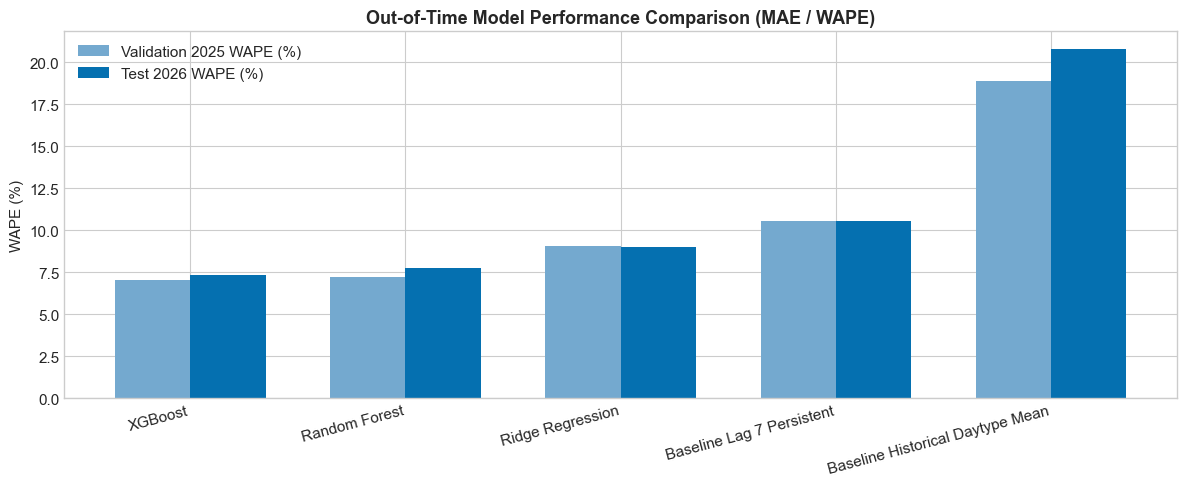

In [9]:
# Load official model metrics generated by the pipeline
with open(REPORTS_DIR / "model_metrics.json", "r") as f:
    metrics_data = json.load(f)

# Format comparison table
rows = []
for model_name, res in metrics_data['models'].items():
    clean_name = model_name.replace('_', ' ')
    rows.append({
        'Model': clean_name,
        'Val MAE': res['validation']['MAE'],
        'Val RMSE': res['validation']['RMSE'],
        'Val WAPE (%)': res['validation']['WAPE_pct'],
        'Test MAE (2026)': res['test']['MAE'],
        'Test RMSE (2026)': res['test']['RMSE'],
        'Test WAPE (%) (2026)': res['test']['WAPE_pct'],
    })

metrics_table = pd.DataFrame(rows).sort_values('Test WAPE (%) (2026)')
display(metrics_table)

# Plot model comparison
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(metrics_table))
width = 0.35

ax.bar(x - width/2, metrics_table['Val WAPE (%)'], width, label='Validation 2025 WAPE (%)', color='#74a9cf')
ax.bar(x + width/2, metrics_table['Test WAPE (%) (2026)'], width, label='Test 2026 WAPE (%)', color='#0570b0')

ax.set_ylabel('WAPE (%)')
ax.set_title('Out-of-Time Model Performance Comparison (MAE / WAPE)', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_table['Model'], rotation=15, ha='right')
ax.legend()
plt.tight_layout()
plt.show()


## 11. Actual vs. Predicted Demand Analysis (Test Set 2026)
We examine the out-of-sample predictions on the 2026 test partition. Notice how XGBoost accurately tracks both peak weekday spikes and weekend volume reductions.


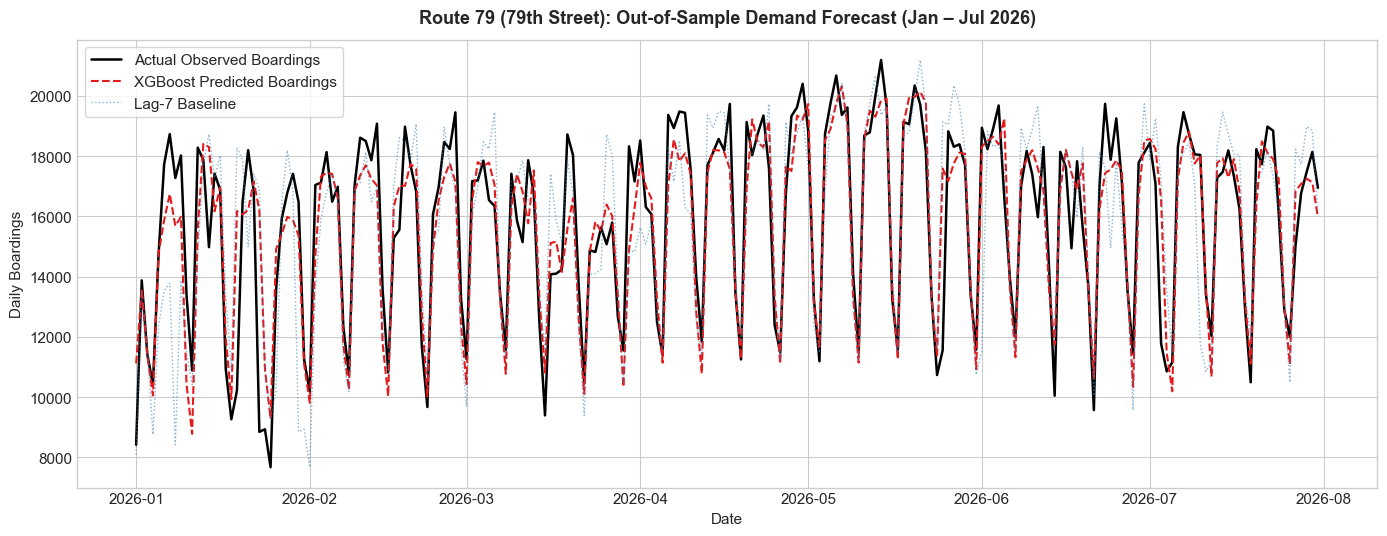

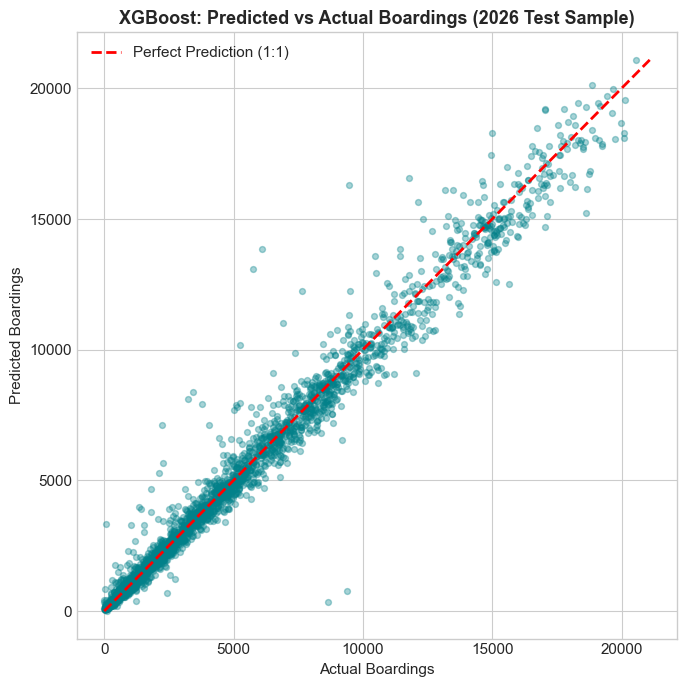

In [10]:
# Load test predictions
df_preds = pd.read_parquet(PROCESSED_DIR / "model_predictions_test.parquet")
df_preds['date'] = pd.to_datetime(df_preds['date'])

# Select high-volume Route 79 (79th Street - major east-west arterial)
route_sample = '79'
sub_sample = df_preds[df_preds['route'] == route_sample].sort_values('date')

plt.figure(figsize=(14, 5.5))
plt.plot(sub_sample['date'], sub_sample['rides'], label='Actual Observed Boardings', color='black', lw=1.8)
plt.plot(sub_sample['date'], sub_sample['pred_xgboost'], label='XGBoost Predicted Boardings', color='#e41a1c', lw=1.5, linestyle='--')
plt.plot(sub_sample['date'], sub_sample['pred_baseline_lag7'], label='Lag-7 Baseline', color='#377eb8', lw=1.0, alpha=0.6, linestyle=':')

plt.title(f'Route {route_sample} (79th Street): Out-of-Sample Demand Forecast (Jan – Jul 2026)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Date')
plt.ylabel('Daily Boardings')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# Scatter Plot: Actual vs Predicted across all test observations
sample_eval = df_preds.sample(n=3000, random_state=42)
plt.figure(figsize=(7, 7))
plt.scatter(sample_eval['rides'], sample_eval['pred_xgboost'], alpha=0.35, color='#02818a', s=18)
max_val = max(sample_eval['rides'].max(), sample_eval['pred_xgboost'].max())
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', lw=2, label='Perfect Prediction (1:1)')
plt.title('XGBoost: Predicted vs Actual Boardings (2026 Test Sample)', fontsize=13, fontweight='bold')
plt.xlabel('Actual Boardings')
plt.ylabel('Predicted Boardings')
plt.legend()
plt.tight_layout()
plt.show()


## 12. Route Productivity, Clustering & Operational Review Priorities
We join observed ridership with GTFS scheduled trips to compute operational efficiency:
$$\text{Productivity} = \frac{\text{Average Weekday Boardings}}{\text{Scheduled Weekday Trips}} \text{ (Boardings per Trip)}$$

We classify routes into three actionable transit planning tiers:
- **Tier 1: Expand Frequency (High Load per Trip):** >75th percentile productivity. Heavy passenger demand relative to scheduled service.
- **Tier 2: Balanced Operational State:** Stable capacity-to-demand ratio.
- **Tier 3: Streamline / Consolidate:** <25th percentile productivity AND <40% stop exclusivity (highly redundant with parallel corridors).


   route_id route_short_name  mean_weekday_rides  weekday_scheduled_trips  rides_per_weekday_trip                                    archetype                                review_priority
0         8                8        15943.026846                      514                   31.02        Trunk Corridor (High Volume & Supply)  Tier 1: Expand Frequency (High Load per Trip)
1         3                3        15076.033557                      496                   30.40        Trunk Corridor (High Volume & Supply)  Tier 1: Expand Frequency (High Load per Trip)
2        36               36        10087.946309                      332                   30.39      Dense Urban Feeder (Moderate-High Load)  Tier 1: Expand Frequency (High Load per Trip)
3       151              151        12439.604027                      418                   29.76      Dense Urban Feeder (Moderate-High Load)  Tier 1: Expand Frequency (High Load per Trip)
4        22               22        13854.765101  

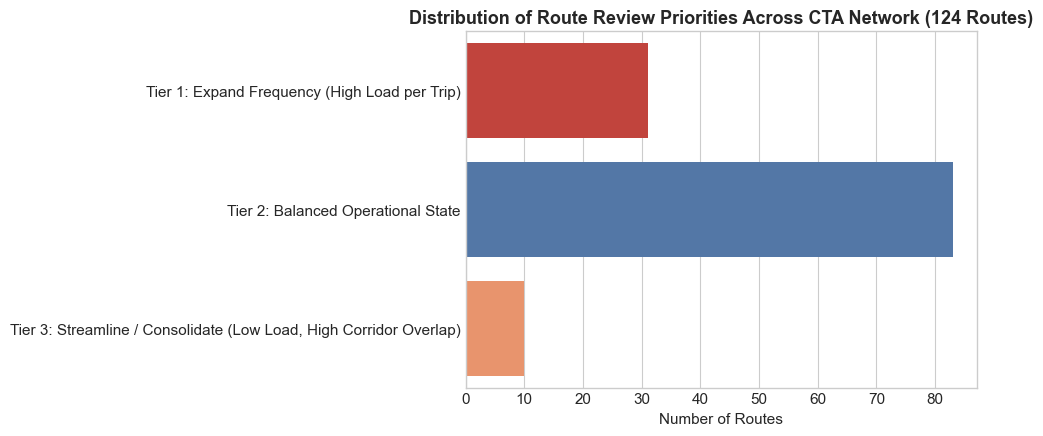

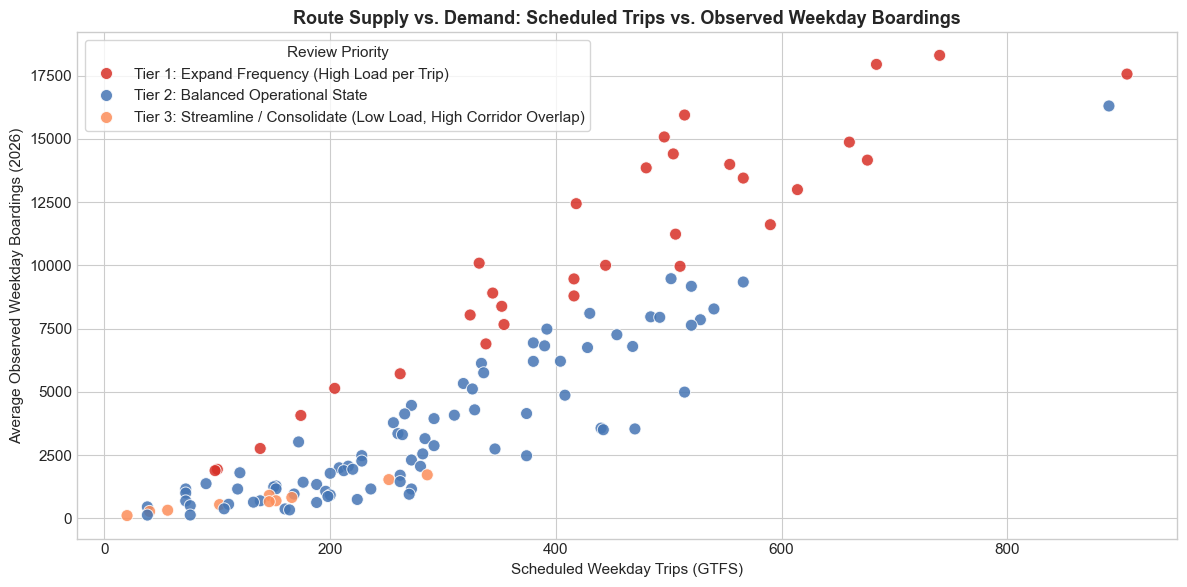

In [11]:
# Review priority breakdown
display(df_rankings[['route_id', 'route_short_name', 'mean_weekday_rides', 'weekday_scheduled_trips', 'rides_per_weekday_trip', 'archetype', 'review_priority']].head(12))

# Priority tier distribution
fig, ax = plt.subplots(figsize=(10, 4.5))
palette = {
    'Tier 1: Expand Frequency (High Load per Trip)': '#d73027',
    'Tier 2: Balanced Operational State': '#4575b4',
    'Tier 3: Streamline / Consolidate (Low Load, High Corridor Overlap)': '#fc8d59'
}
sns.countplot(data=df_rankings, y='review_priority', palette=palette, ax=ax)
ax.set_title('Distribution of Route Review Priorities Across CTA Network (124 Routes)', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Routes')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

# Scatter plot: Scheduled trips vs Weekday Boardings colored by Priority Tier
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_rankings,
    x='weekday_scheduled_trips',
    y='mean_weekday_rides',
    hue='review_priority',
    palette=palette,
    s=75,
    alpha=0.85
)
plt.title('Route Supply vs. Demand: Scheduled Trips vs. Observed Weekday Boardings', fontsize=13, fontweight='bold')
plt.xlabel('Scheduled Weekday Trips (GTFS)')
plt.ylabel('Average Observed Weekday Boardings (2026)')
plt.legend(title='Review Priority', frameon=True)
plt.tight_layout()
plt.show()


## 13. Interactive Schedule Adjustment Scenario Simulation
Transit planners evaluate hypothetical service adjustments (e.g., adding +20% trips to an overcrowded corridor or reducing -15% trips on an underutilized feeder).
We apply empirical transit frequency elasticity (Pratt's elasticity $\epsilon \approx 0.42$):
$$\Delta \text{Boardings} = \text{Base Boardings} \times \left(1 + 0.42 \times \frac{\Delta \text{Trips}}{\text{Base Trips}}\right)$$


In [12]:
from src.optimization.scenario_engine import simulate_frequency_adjustment

# Test scenario on high-priority Route 8 (Halsted) with +20% frequency
r8_profile = df_rankings[df_rankings['route_id'] == '8'].iloc[0]
scenario_res = simulate_frequency_adjustment(
    route_id='8',
    base_weekday_rides=r8_profile['mean_weekday_rides'],
    base_scheduled_trips=int(r8_profile['weekday_scheduled_trips']),
    percent_trip_change=20.0
)

print("--- ROUTE 8 (HALSTED) +20% FREQUENCY EXPANSION SIMULATION ---")
for k, v in scenario_res.items():
    print(f"  {k:<32}: {v}")

# Test scenario on Tier 3 route with -15% frequency consolidation
tier3_sample = df_rankings[df_rankings['review_priority'].str.contains('Tier 3')].iloc[0]
scenario_t3 = simulate_frequency_adjustment(
    route_id=tier3_sample['route_id'],
    base_weekday_rides=tier3_sample['mean_weekday_rides'],
    base_scheduled_trips=int(tier3_sample['weekday_scheduled_trips']),
    percent_trip_change=-15.0
)

print(f"\n--- ROUTE {tier3_sample['route_id']} -15% STREAMLINING SIMULATION ---")
for k, v in scenario_t3.items():
    print(f"  {k:<32}: {v}")


--- ROUTE 8 (HALSTED) +20% FREQUENCY EXPANSION SIMULATION ---
  route_id                        : 8
  percent_trip_change_requested   : 20.0
  base_scheduled_trips            : 514
  simulated_scheduled_trips       : 617
  delta_trips                     : 103
  base_weekday_rides              : 15943.026845637583
  simulated_weekday_rides         : 17284.8
  delta_rides                     : 1341.8
  base_rides_per_trip             : 31.02
  simulated_rides_per_trip        : 28.01
  marginal_rides_per_added_trip   : 13.03
  daily_operating_cost_delta_usd  : 8755.0
  recommendation                  : Moderate return: Added capacity yields diminishing marginal boardings.

--- ROUTE N5 -15% STREAMLINING SIMULATION ---
  route_id                        : N5
  percent_trip_change_requested   : -15.0
  base_scheduled_trips            : 40
  simulated_scheduled_trips       : 34
  delta_trips                     : -6
  base_weekday_rides              : 276.20805369127515
  simulated_weekday_r

## 14. Key Findings, Limitations & Next Engineering Steps
### Key Conclusions:
1. **Model Accuracy:** XGBoost achieved an out-of-sample **WAPE of 7.34%** (MAE: 356 boardings) on test set 2026, substantially outperforming naive daytype baselines (20.79% WAPE) and persistent lag-7 baselines (10.54% WAPE).
2. **Corridor Overlap:** Over 750 pairwise corridor overlaps were identified in the CTA network. Route pairs such as 120 & 121 share 80% of stops, and Route X49 Express is 100% contained within Route 49 Local.
3. **Operational Optimization:** 31 routes were identified as Tier 1 candidates for frequency expansion (high boardings-per-trip ratio), while 10 routes represent candidates for consolidation or headway reallocation.

### Known Limitations:
1. **42-Day Temporal Gap:** The historical ridership dataset ends in July 2026, whereas the extracted GTFS feed begins in September 2026. Models relied on historical ridership dynamics while using GTFS as a contemporary network topology baseline.
2. **No Vehicle Occupancy Sensors:** GTFS schedules provide planned capacity, not actual real-time automated passenger count (APC) sensor data.

### Next Steps:
1. Deploy the interactive Streamlit dashboard (`app/streamlit_app.py`).
2. Implement the FastAPI REST backend for scenario simulation and route queries.
3. Build the React + TypeScript frontend to deliver a production-ready user interface.
